# Step 2b (Kaggle) — ImageNet-100 training pairs

**Before running (Notebook → right panel):**
- *Accelerator:* GPU T4 (×1 or ×2).
- *Internet:* **On** (needs a phone-verified account).
- *Add Input → Datasets:* `ambityga/imagenet100` and `rickyyyyyyy/torchvision-stanford-cars`.

What it does:
1. Arranges ImageNet-100 into the folder layout the authors' `ImageNet100` class expects (file symlinks, no copying).
2. Creates the `preprocessed_data` folder (224×224 resize + centre crop of each original). **The authors' training code reads this folder but the repository does not contain the code that creates it** — we recreate it with the same transform and JPEG quality the authors use for the attacked images.
3. Generates the attacked training images with the authors' generator (seed 300).
4. Encodes both versions with frozen CLIP ViT-B/32 and saves `train_imagenet100.pt` (≈0.3 GB). Training a DP vector later only needs this file.

Outputs go to `/kaggle/working/cache` → click **Save Version** (Save & Run All) so they are kept.

In [1]:
# 1) Environment, disk, inputs
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader
!df -h /kaggle/working /tmp | tail -2
!ls /kaggle/input
import os, sys
BASE  = "/tmp/work"                     # scratch space (not saved)
CACHE = "/kaggle/working/cache"         # saved as notebook output
os.makedirs(BASE, exist_ok=True); os.makedirs(CACHE, exist_ok=True)

Tesla T4, 15360 MiB
Tesla T4, 15360 MiB
/dev/loop2       20G   64K   20G   1% /kaggle/working
overlay         8.0T  7.1T  967G  89% /


In [2]:
# 2) Dependencies
!pip -q install ftfy regex git+https://github.com/openai/CLIP.git
import torch, torchvision, PIL
print("python", sys.version.split()[0], "| torch", torch.__version__, "| torchvision", torchvision.__version__, "| Pillow", PIL.__version__)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
python 3.13.16 | torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | Pillow 13.0.0


In [3]:
# Original code, pinned, plus the two compatibility patches from Step 1
import os, pathlib, subprocess
os.chdir(BASE)
if not os.path.isdir("Defense-Prefix"):
    subprocess.run("git clone -q https://github.com/azuma164/Defense-Prefix.git", shell=True, check=True)
os.chdir(f"{BASE}/Defense-Prefix")
subprocess.run("git checkout -q 50d7887", shell=True, check=True)
p = pathlib.Path("datasets/utils/make_dataset_train.py"); s = p.read_text()
if "_textsize" not in s:
    helper = "\ndef _textsize(draw, text, font):\n    # Replacement for ImageDraw.textsize (removed in Pillow 10).\n    l, t, r, b = draw.multiline_textbbox((0, 0), text, font=font)\n    return r, b\n"
    s = s.replace("random.seed(300)", "random.seed(300)\n" + helper, 1).replace("imagedraw.textsize(text, font=font)", "_textsize(imagedraw, text, font)")
    p.write_text(s)
e = pathlib.Path("eval.py"); s = e.read_text()
e.write_text(s.replace("torch.load(args.tokens_path)", "torch.load(args.tokens_path, map_location=device, weights_only=False)"))
print(subprocess.run("git rev-parse HEAD && git diff --stat", shell=True, capture_output=True, text=True).stdout)

50d7887017b295e76b15e56c137ab47e68264448
 datasets/utils/make_dataset_train.py | 10 ++++++++--
 eval.py                              |  2 +-
 2 files changed, 9 insertions(+), 3 deletions(-)



In [4]:
%%writefile /tmp/work/Defense-Prefix/cache_features.py
"""Cache CLIP ViT-B/32 image features for one evaluation dataset of the Defense-Prefix paper.

Run from the root of the Defense-Prefix repository, one dataset per process
(the authors' attack generator seeds `random` once at import, and the authors
ran eval.py once per dataset, so one process per dataset reproduces their setup).

The dataset objects are the authors' own classes from `datasets/`, built with the
same arguments as the authors' `dataset.py`, so splits, labels, class names,
prompt templates and synthetic attacks are exactly theirs. The only difference
from `dataset.py` is that `download` is configurable (Stanford Cars can no longer
be downloaded through torchvision).

Features are computed exactly as in the authors' eval.py: fp16 CLIP image
features, L2-normalised. Evaluating any Defense-Prefix token on these cached
features gives the same predictions as eval.py.
"""
import argparse
import json
import os
import subprocess
import sys
import time

import clip
import torch
from torch.utils.data import DataLoader
from tqdm import tqdm

sys.path.insert(0, os.getcwd())

REAL_WORLD = {"rta-100", "paint", "disentangling"}
device = "cuda" if torch.cuda.is_available() else "cpu"


def build(name, preprocess, root="datasets", download=True):
    """Mirror of the authors' dataset.py with a configurable download flag."""
    if name == "imagenet":
        from datasets.ImageNetV2 import ImageNetValDataset
        return ImageNetValDataset(location=root, transform=preprocess)
    if name == "caltech":
        from datasets.caltech101 import Caltech101
        return Caltech101(root=root, transform=preprocess, download=download, make_typographic_dataset=True)
    if name == "pets":
        from datasets.oxford_pets import OxfordIIITPet
        return OxfordIIITPet(root=root, split="test", transform=preprocess, download=download, make_typographic_dataset=True)
    if name == "cars":
        from datasets.stanford_cars import StanfordCars
        return StanfordCars(root=root, split="test", transform=preprocess, download=False, make_typographic_dataset=True)
    if name == "flowers":
        from datasets.flowers102 import Flowers102
        return Flowers102(root=root, split="test", transform=preprocess, download=download, make_typographic_dataset=True)
    if name == "food":
        from datasets.food101 import Food101
        return Food101(root=root, split="test", transform=preprocess, download=download)
    if name == "aircraft":
        from datasets.fgvcaircraft import FGVCAircraft
        return FGVCAircraft(root=root, split="test", transform=preprocess, download=download)
    if name == "dtd":
        from datasets.dtd import DTD
        return DTD(root=root, split="test", transform=preprocess, download=download)
    if name == "eurosat":
        from datasets.eurosat import EuroSAT
        return EuroSAT(root=root, split="test", transform=preprocess, download=download)
    if name == "sun":
        from datasets.sun397 import SUN397
        return SUN397(root=root, split="test", transform=preprocess, download=False)
    if name == "paint":
        from datasets.paint_ta import PAINTDataset
        return PAINTDataset(root=root, transform=preprocess)
    if name == "disentangling":
        from datasets.disentangling_ta import DisentanglingDataset
        return DisentanglingDataset(root=root, transform=preprocess)
    if name == "rta-100":
        from datasets.rta100 import RTA100
        return RTA100(root=root, transform=preprocess)
    raise ValueError(name)


def git_commit():
    try:
        return subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip()
    except Exception:
        return "unknown"


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--dataset", required=True)
    ap.add_argument("--out", required=True, help="folder for <dataset>.pt")
    ap.add_argument("--root", default="datasets")
    ap.add_argument("--batch_size", type=int, default=256)
    ap.add_argument("--workers", type=int, default=2)
    args = ap.parse_args()
    os.makedirs(args.out, exist_ok=True)

    model, preprocess = clip.load("ViT-B/32", device=device)
    model.eval()

    t0 = time.time()
    data = build(args.dataset, preprocess, root=args.root)  # also generates the synthetic attack images (seed 300)
    prep_s = time.time() - t0

    loader = DataLoader(data, batch_size=args.batch_size, shuffle=False, num_workers=args.workers)
    real = args.dataset in REAL_WORLD
    clean, attack, labels = [], [], []
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t1 = time.time()
    with torch.no_grad():
        for original_image, typographic_image, target in tqdm(loader, desc=args.dataset):
            f = model.encode_image(original_image.to(device))
            f /= f.norm(dim=-1, keepdim=True)          # identical to eval.py
            clean.append(f.cpu())
            if not real:
                g = model.encode_image(typographic_image.to(device))
                g /= g.norm(dim=-1, keepdim=True)
                attack.append(g.cpu())
            labels.append(torch.as_tensor(target))
    enc_s = time.time() - t1

    out = {
        "dataset": args.dataset,
        "real_world": real,
        "classes": list(data.classes),
        "template": data.templates[0],
        "labels": torch.cat(labels).long(),
        "clean": torch.cat(clean),                       # for real-world sets these images contain the attack
        "attack": torch.cat(attack) if attack else None,
        "meta": {
            "n_images": len(data),
            "n_classes": len(data.classes),
            "prepare_seconds": round(prep_s, 1),
            "encode_seconds": round(enc_s, 1),
            "peak_gpu_mem_mb": round(torch.cuda.max_memory_allocated() / 2**20, 1) if device == "cuda" else None,
            "gpu": torch.cuda.get_device_name(0) if device == "cuda" else "cpu",
            "torch": torch.__version__,
            "repo_commit": git_commit(),
            "model": "ViT-B/32",
        },
    }
    path = os.path.join(args.out, f"{args.dataset}.pt")
    torch.save(out, path)
    print(json.dumps({"saved": path, **out["meta"]}, indent=1))


if __name__ == "__main__":
    main()


Writing /tmp/work/Defense-Prefix/cache_features.py


## ImageNet-100

In [6]:
# 3) Arrange ImageNet-100 as  <root>/data/train/<wnid>/<image>  +  <root>/data/Labels.json
import glob, json, shutil, pathlib
src = os.path.dirname(glob.glob("/kaggle/input/**/Labels.json", recursive=True)[0])
print("ImageNet-100 input:", src, sorted(os.listdir(src)))
ROOT = pathlib.Path(f"{BASE}/ImageNet")
train = ROOT / "data" / "train"
if not train.exists():
    train.mkdir(parents=True)
    shutil.copy(f"{src}/Labels.json", ROOT / "data" / "Labels.json")
    for part in sorted(glob.glob(f"{src}/train.X*")):
        for wnid_dir in sorted(os.listdir(part)):
            (train / wnid_dir).mkdir(exist_ok=True)
            for f in os.listdir(f"{part}/{wnid_dir}"):
                os.symlink(f"{part}/{wnid_dir}/{f}", train / wnid_dir / f)
n_cls = len(os.listdir(train)); n_img = sum(len(os.listdir(train / d)) for d in os.listdir(train))
print(n_cls, "classes,", n_img, "training images")   # expect 100 classes, ~130k images

ImageNet-100 input: /kaggle/input/datasets/ambityga/imagenet100 ['Labels.json', 'train.X1', 'train.X2', 'train.X3', 'train.X4', 'val.X']
100 classes, 130000 training images


In [7]:
# 4) preprocessed_data: the authors' transform (Resize 224 bicubic + CenterCrop 224), saved like their attack images (JPEG quality=100)
from concurrent.futures import ProcessPoolExecutor
from PIL import Image
from torchvision import transforms
PRE = ROOT / "preprocessed_data" / "train"
tf = transforms.Compose([transforms.Resize(224, interpolation=Image.BICUBIC), transforms.CenterCrop(224)])
def prep(rel):
    out = PRE / rel
    if out.exists(): return
    out.parent.mkdir(parents=True, exist_ok=True)
    img = Image.open(train / rel)
    if img.mode not in ("RGB", "L"): img = img.convert("RGB")   # JPEG cannot store e.g. CMYK/P reliably; CLIP preprocess converts to RGB anyway
    tf(img).save(out, quality=100)
rels = [str(p.relative_to(train)) for p in train.rglob("*") if p.is_file()]
import time; t0 = time.time()
with ProcessPoolExecutor(os.cpu_count()) as ex:
    list(ex.map(prep, rels, chunksize=256))
print(len(rels), "preprocessed in", round(time.time() - t0), "s")

130000 preprocessed in 2669 s


### 5) Generate attacked images (authors' code, seed 300, single process) and cache features of both versions

⚠️ If this step is interrupted, delete `/tmp/work/ImageNet/typographic_attack_data_3fonts` before re-running: the authors' code skips generation whenever that folder exists.

In [8]:
%%writefile /tmp/work/Defense-Prefix/cache_train.py
import os, sys, time, json, subprocess, torch, clip
from torch.utils.data import DataLoader
from tqdm import tqdm
sys.path.insert(0, os.getcwd())
from datasets.ImageNet100 import ImageNet100
device = "cuda"
root, out = sys.argv[1], sys.argv[2]
model, preprocess = clip.load("ViT-B/32", device=device); model.eval()
t0 = time.time()
data = ImageNet100(root, split="train", preprocess=preprocess)      # generates typographic images if missing
gen_s = time.time() - t0
loader = DataLoader(data, batch_size=512, shuffle=False, num_workers=os.cpu_count())
orig, typo, labels = [], [], []
torch.cuda.reset_peak_memory_stats(); t1 = time.time()
with torch.no_grad():
    for a, b, y in tqdm(loader):
        f = model.encode_image(a.to(device)); orig.append(torch.nn.functional.normalize(f, dim=-1).cpu())
        g = model.encode_image(b.to(device)); typo.append(torch.nn.functional.normalize(g, dim=-1).cpu())
        labels.append(y)
meta = {"n_images": len(data), "classes_order": "filesystem order of data/train (stored below)",
        "generate_seconds": round(gen_s), "encode_seconds": round(time.time() - t1),
        "peak_gpu_mem_mb": round(torch.cuda.max_memory_allocated() / 2**20), "gpu": torch.cuda.get_device_name(0),
        "torch": torch.__version__, "repo_commit": subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip()}
torch.save({"classes": data.classes, "labels": torch.cat(labels), "original": torch.cat(orig), "typographic": torch.cat(typo),
            "files": [str(f) for f in data._files], "meta": meta}, f"{out}/train_imagenet100.pt")
print(json.dumps(meta, indent=1))

Writing /tmp/work/Defense-Prefix/cache_train.py


In [9]:
os.chdir(f"{BASE}/Defense-Prefix")
!python cache_train.py {ROOT} {CACHE} 2>&1 | grep -v -E "^(/|n[0-9]{8}|\{)" | tail -15
!ls -la {CACHE}

100%|████████████████████████████████████████| 338M/338M [00:02<00:00, 155MiB/s]
Traceback (most recent call last):
  File "/tmp/work/Defense-Prefix/cache_train.py", line 10, in <module>
    data = ImageNet100(root, split="train", preprocess=preprocess)      # generates typographic images if missing
  File "/tmp/work/Defense-Prefix/datasets/ImageNet100.py", line 186, in __init__
    with open(Path(root) / 'data' / 'Labels.json') as f:
         ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
FileNotFoundError: [Errno 2] No such file or directory: '{ROOT}/data/Labels.json'
total 8
drwxr-xr-x 2 root root 4096 Nov  5 16:48 .
drwxr-xr-x 4 root root 4096 Nov  5 16:48 ..


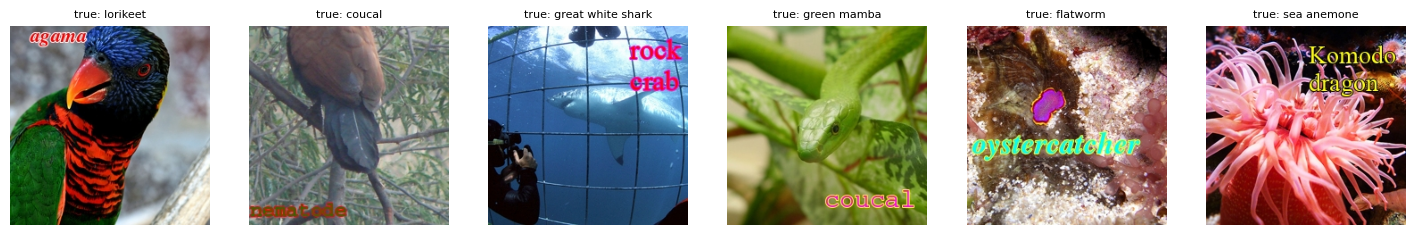

In [20]:
# Six example attacked TRAINING images, made with the authors' generator (for the report figure)
import glob, json, random, pathlib, matplotlib.pyplot as plt
from PIL import Image
os.chdir(f"{BASE}/Defense-Prefix")
from datasets.utils.make_dataset_train import make_image_text      # authors' generator (patched textsize)
src = os.path.dirname(glob.glob("/kaggle/input/**/Labels.json", recursive=True)[0])
id2cls = json.load(open(f"{src}/Labels.json"))
part = pathlib.Path(sorted(glob.glob(f"{src}/train.X*"))[0])
wnids = sorted(os.listdir(part))
classes = [id2cls[w].split(",")[0] for w in wnids]
rng = random.Random(0)
picks = [(w, rng.choice(sorted(os.listdir(part / w)))) for w in rng.sample(wnids, 6)]
out = pathlib.Path(f"{W}/train_attack_examples") if "W" in globals() else pathlib.Path("/kaggle/working/train_attack_examples")
fig, axs = plt.subplots(1, 6, figsize=(18, 3.5))
for ax, (w, f) in zip(axs, picks):
    make_image_text(f"{w}/{f}", classes, part, out, wnids.index(w))
    ax.imshow(Image.open(out / w / f)); ax.axis("off"); ax.set_title(f"true: {classes[wnids.index(w)]}", fontsize=8)
plt.savefig("/kaggle/working/train_attack_examples.png", dpi=150, bbox_inches="tight"); plt.show()

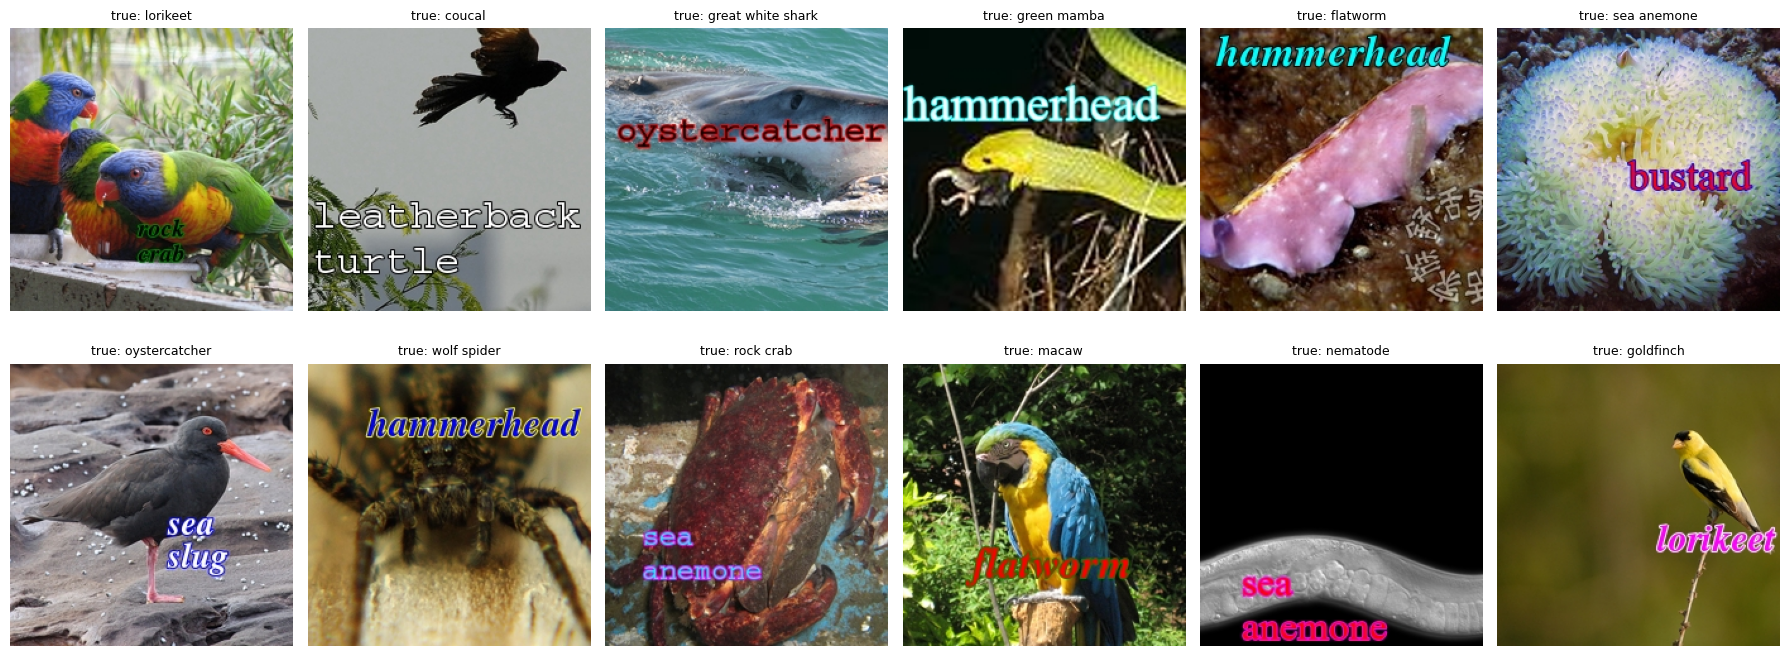

In [18]:
# Twelve example attacked TRAINING images (2 rows x 6), made with the authors' generator (for the report figure)
import glob, json, random, pathlib, matplotlib.pyplot as plt
from PIL import Image
os.chdir(f"{BASE}/Defense-Prefix")
from datasets.utils.make_dataset_train import make_image_text      # authors' generator (patched textsize)
src = os.path.dirname(glob.glob("/kaggle/input/**/Labels.json", recursive=True)[0])
id2cls = json.load(open(f"{src}/Labels.json"))
part = pathlib.Path(sorted(glob.glob(f"{src}/train.X*"))[0])
wnids = sorted(os.listdir(part))
classes = [id2cls[w].split(",")[0] for w in wnids]
N_ROWS, N_COLS = 2, 6
rng = random.Random(0)
picks = [(w, rng.choice(sorted(os.listdir(part / w)))) for w in rng.sample(wnids, N_ROWS * N_COLS)]
out = pathlib.Path("/kaggle/working/train_attack_examples")
fig, axs = plt.subplots(N_ROWS, N_COLS, figsize=(18, 3.6 * N_ROWS))
for ax, (w, f) in zip(axs.flat, picks):
    make_image_text(f"{w}/{f}", classes, part, out, wnids.index(w))
    ax.imshow(Image.open(out / w / f)); ax.axis("off"); ax.set_title(f"true: {classes[wnids.index(w)]}", fontsize=9)
plt.tight_layout()
plt.savefig("/kaggle/working/train_attack_examples.png", dpi=150, bbox_inches="tight"); plt.show()

In [12]:
!ls -la /kaggle/working/cache
!ls /tmp/work 2>/dev/null
!find /tmp/work/ImageNet/typographic_attack_data_3fonts -type f 2>/dev/null | wc -l
!find /tmp/work/ImageNet/preprocessed_data -type f 2>/dev/null | wc -l

total 8
drwxr-xr-x 2 root root 4096 Nov  5 16:48 .
drwxr-xr-x 4 root root 4096 Nov  5 16:48 ..
Defense-Prefix	ImageNet
0
130000


In [13]:
%cd /tmp/work/Defense-Prefix
!rm -rf /tmp/work/ImageNet/typographic_attack_data_3fonts
!nvidia-smi -L
!ls cache_train.py
!python cache_train.py /tmp/work/ImageNet /kaggle/working/cache > /kaggle/working/cache_train.log 2>&1; tail -25 /kaggle/working/cache_train.log

/kaggle/working
GPU 0: Tesla T4 (UUID: GPU-5049cb97-589a-4d69-9cdf-252565aad42d)
GPU 1: Tesla T4 (UUID: GPU-23cf27fd-0b0e-7a75-a145-c5f7603abf64)
cache_train.py
/tmp/work/ImageNet/data/train/n02006656/n02006656_4439.JPEG
/tmp/work/ImageNet/data/train/n02006656/n02006656_21102.JPEG
/tmp/work/ImageNet/data/train/n02006656/n02006656_5847.JPEG
/tmp/work/ImageNet/data/train/n02006656/n02006656_9880.JPEG
/tmp/work/ImageNet/data/train/n02006656/n02006656_190.JPEG
/tmp/work/ImageNet/data/train/n02006656/n02006656_18270.JPEG
/tmp/work/ImageNet/data/train/n02006656/n02006656_580.JPEG
/tmp/work/ImageNet/data/train/n02006656/n02006656_4235.JPEG
/tmp/work/ImageNet/data/train/n02006656/n02006656_4977.JPEG
/tmp/work/ImageNet/data/train/n02006656/n02006656_8123.JPEG
/tmp/work/ImageNet/data/train/n02006656/n02006656_6291.JPEG
/tmp/work/ImageNet/data/train/n02006656/n02006656_540.JPEG
/tmp/work/ImageNet/data/train/n02006656/n02006656_838.JPEG
/tmp/work/ImageNet/data/train/n02006656/n02006656_9320.JPEG
1

**Done.** Click **Save Version → Save & Run All** (or download `/kaggle/working/cache/*.pt`).
- `train_imagenet100.pt` → keep on Kaggle (attach this notebook's output as input to the training notebook); a copy in Drive is a useful backup.